Import the modules that will be used.

In [5]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

%matplotlib inline

## Exercise 11.1

Determine by counting the number of mathematical operations the complexity of:

1. Dot product between two vectors
1. Matrix-vector product
1. Matrix-matrix product

for vectors of length $n$ and matrices of size $n \times n$.

This is a reasoning exercise - you do not need to write a program. Express your answers in text and using LaTeX in a Markdown cell.


### Optional

Test the complexity experimentally with your own functions for performing the operations, and
with the NumPy 'vectorised' equivalents.

1. The dot product requires the multiplication of each value in the array once. Number of operations is exactly proportional to the number,n, of each vector. Therefore n dot n operation is only $O(n)$.
2. A matrix vector product requires a number of operations proportional to the number of columns in the matrix (or number of rows in vector). This is repeated for an n number of rows in the matrix, therefore it is $O(n^2)$
3. The same number of operations is done as the matrix-vector product, but this time it is also repeated across the n number of columns in the matrix (not just the single column in a vector), increasing the complexity by n, resulting in a an $O(n^3)$.     

## Exercise 11.2

For the recursive factorial algorithm in Activity 04, determine the algorithmic complexity by inspecting your implementation of the algorithm. Test this against numerical experiments.

### Solution

Recall the factorial algorithm from Activity 04.4:

In [6]:
def factorial(n):
    if n == 0:
        return 1
    else:
        return factorial(n - 1)*n

The function calls itself (recursively) $n$ times, hence it has complexity $O(n)$. We test this below and plot
the times.

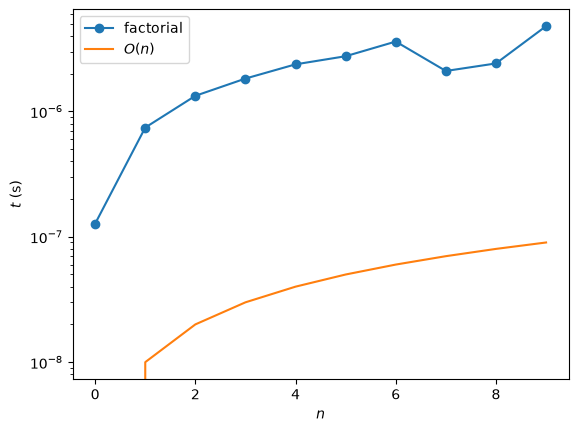

In [7]:
# Create array of problem sizes we want to test (powers of 2)
N = np.arange(0, 10)

# Time factorial  
times = []
for n in N:
    t = %timeit -o -q -r 3 factorial(n)
    times.append(t.best)

# Plot timing
plt.semilogy(N, times, marker='o', label='factorial')

# Show reference line of O(n)
plt.semilogy(N, 1e-8*N, label='$O(n)$')

# Add labels and legend
plt.xlabel('$n$')
plt.ylabel('$t$ (s)')
plt.legend(loc=0)

plt.show()

## Exercise 11.3

Determine experimentally the complexity of computing the determinant of a matrix. You can generate an $n \times n$ matrix using:

In [8]:
n = 100
A = np.random.rand(n, n)

and the determinant can be computed by:

In [9]:
det = np.linalg.slogdet(A)

Be sure that you test for sufficiently large $n$ to get into the 'large' $n$ regime.

### Solution

Time computation of determinant:

In [ ]:
# Create array of problem sizes we want to test (powers of 2)
N = 2**np.arange(2, 12)
 
# Time determinant  
times = []
for n in N:
    A = np.random.rand(n, n)
    t = %timeit -o -q np.linalg.slogdet(A)
    times.append(t.best)

Plot result:

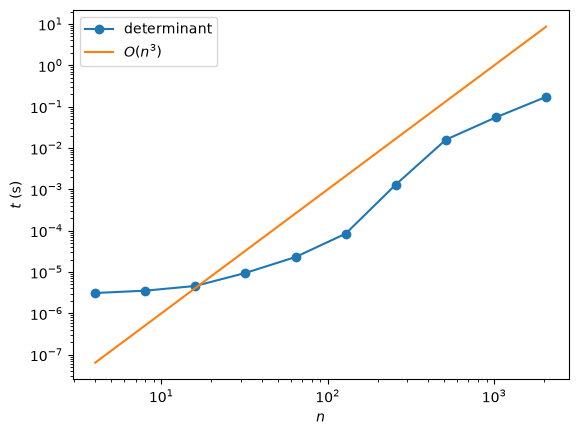

In [38]:
# Plot timing
plt.loglog(N, times, marker='o', label='determinant')

# Show reference line of O(n)
plt.loglog(N, 1e-9*N**3, label='$O(n^3)$')

# Add labels and legend
plt.xlabel('$n$')
plt.ylabel('$t$ (s)')
plt.legend(loc=0)

plt.show()

The determinant seems to be an algorithm of $O(n^3)$ as that's the line that fits the closest. In reality, the algorithm completes in a greater than expected time for small values of N likely because calling the numpy function takes a finite time, however the slope is flatter than 3 so the order is lower. 
As n approaches larger values the curves are almost parallel which is expected for an $O(n^3)$ algorithm.
Then at large values the slope of the line becomes flatter again, perhaps showing that numpy switches from single core to multicore processing to speed up calculations.